# Анализ серии кадров с изображением NEA

Ноутбук выполняет астрометрические измерения астероида (NEA) на серии FITS-кадров и сравнивает
их с эфемеридой **NASA JPL Horizons**. Номер (обозначение) астероида берется из поля `TARGET`
заголовка каждого кадра, код обсерватории MPC - из поля `MPC`.

**Конвейер обработки одного кадра** (`process_frame`):

| шаг | функция | что делает |
|---|---|---|
| 1 | `read_frame` | читает FITS: изображение, WCS, фильтр, момент экспозиции, TARGET, код обсерватории |
| 2 | `select_reference_stars` | опорные звезды Gaia DR3 в кадре, с учетом собственных движений на момент съемки |
| 3 | `get_asteroid_position` | эфемеридные координаты астероида из Horizons и его предсказанное положение в пикселях |
| 4 | `measure_star_psf_shape` | средняя форма звездного профиля (A,B,C) по кадру |
| 5 | `astrometric_calibration` | редукция (x,y) → (ξ,η) по опорным звездам с отбраковкой выбросов |
| 6 | `measure_asteroid` | гауссов фит изображения астероида → (ξ,η) → (α,δ) и O-C относительно Horizons |
| 7 | `build_result_row` | строка итоговой таблицы измерений |

**Как пользоваться:** задайте папку серии в разделе 1 и выполните ячейки по порядку.
Раздел 7 показывает серию и эфемериды, раздел 8 - подробный разбор одного кадра со всеми
контрольными картинками, разделы 9-10 - пакетную обработку и итоги по серии.

**Обозначения на картинках:** черные кружки - опорные звезды Gaia, зеленые - звезды, вошедшие в
астрометрическое решение, оранжевые - отбракованные, красный - предсказанное по Horizons
положение астероида, синий крестик - измеренное.

In [1]:
from math import *
import numpy as np

import pandas as pd
import requests
import io

from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.time import Time
from astropy.time import TimeDelta

from scipy.optimize import curve_fit

from astropy import units as u
from astropy.coordinates import SkyCoord

import glob
import os
import re
import time
import warnings
from astroquery.jplhorizons import Horizons
warnings.simplefilter('ignore', FITSFixedWarning) # 'datfix' и т.п. - astropy сам чинит заголовок, шум в выводе не нужен

# INTERACTIVE = False - статические картинки (inline): сохраняются в самом .ipynb и видны без ядра,
# в том числе другим пользователям и в nbviewer/GitHub. True - интерактивные (ipympl, zoom/pan),
# но они живут только в работающем ядре: после перезапуска ядра или повторного открытия ноутбука
# на их месте будет "Error displaying widget: model not found" - тогда просто перевыполните ячейки.
INTERACTIVE = False

import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'widget' if INTERACTIVE else 'inline')
except NameError:
    pass # запуск как обычный .py-скрипт - используется backend по умолчанию
import matplotlib.pyplot as plt
from matplotlib import cm
rgray = matplotlib.colormaps['gray'].reversed()

## 1. Параметры обработки

Здесь задается папка с серией и все настраиваемые параметры. Остальные ячейки менять не нужно.

In [28]:
neapath = '/Users/ymax/Documents/fits/20260929' # папка с кадрами одной серии
FILE_MASK = '*_R_*.fits'  # какие кадры серии обрабатывать (здесь - только фильтр R)
vis_filename = None       # кадр для подробного разбора (раздел 8); None - средний кадр серии

limmag1,limmag2 = 10.0,17.0 # диапазон блеска (G) для опорных звезд
fov = 0.4                   # размер области выборки из Gaia, градусы (должен накрывать кадр целиком)
bdr = 20                    # бордюр, пиксели: звезды ближе к краю кадра не используются
STAR_HALF_WIDTH = 8        # полуразмер окна (пиксели) вокруг звезды/астероида для фита профиля
CAL_ORDER = 3               # степень полинома астрометрической модели (x,y)->(ksi,eta)
CAL_NMIN, CAL_RMAX = 5, 0.2 # отбраковка опорных звезд: мин. запас числа звезд и порог невязки, arcsec
DEFAULT_MPC_CODE = '217'    # код обсерватории, если в заголовке нет поля MPC (217 - Ассы-Тургень)
omc_thresh = 1.0            # arcsec - измерения с |O-C| больше порога помечаются как сомнительные
BLEND_PIX = 15              # px - звезда Gaia ближе этого к астероиду искажает фит (флаг 'b')
MAX_SHIFT_PIX = 3           # px - фит ушел от эфемеридного положения дальше этого (флаг 's')
MAX_ERR_PIX = 0.5           # px - формальная ошибка центроида больше этого (флаг 'e')

# что означает DATE-OBS: 'start' - начало накопления (к нему добавляется EXPTIME/2), 'mid' - уже
# середина. В стеках /blink комментарий к DATE-OBS говорит 'mean mid-exposure', но O-C серии
# 20260929 относительно Horizons показывают сдвиг вдоль трека, соответствующий +29+-3 с, т.е.
# фактически DATE-OBS - начало стека. Проверяйте по оценке сдвига времени в разделе 10.
DATE_OBS_MODE = 'start'

if not neapath.endswith('/'):
    neapath += '/'

## 2. Каталог Gaia и геометрия

Функции выборки опорных звезд из Gaia DR3 (сервер `sfa.puldb.ru`, с кэшем на диске) и
стандартные преобразования между экваториальными и тангенциальными координатами.

In [29]:
# выборка данных из Gaia DR3 http://sfa.puldb.ru:9810
# кадры из разных серий (разных ночей/папок) могут смотреть в разные точки неба,
# поэтому каталог запрашивается не один раз на весь скрипт, а один раз на серию -
# серией считаются все кадры в одной папке (они соседние и близкие по времени, поле одно и то же).
# Результат кэшируется в памяти на время работы скрипта и на диск в gaia_<ra>_<dec>.csv, чтобы
# не запрашивать сервер заново при повторных запусках
_gaia_cache = {}
def get_gaia_box(filename,RAc,DECc,fov):
    series = os.path.dirname(filename) # все кадры одной папки = одна серия = один и тот же df
    if series in _gaia_cache:
        return _gaia_cache[series]
    cache_file = f'gaia_{RAc:.2f}_{DECc:.2f}.csv'
    if os.path.exists(cache_file):
        gdf = pd.read_csv(cache_file)
    else:
        response = requests.get(f'http://sfa.puldb.ru:9810?cmd=box&ra={RAc}&dec={DECc}&fov={fov}', timeout=300)
        gdf = pd.read_csv(io.StringIO(response.content.decode('utf-8')))
        gdf.to_csv(cache_file, index=False)
    _gaia_cache[series] = gdf
    return gdf

# стандартный набор - функции для расчета углов, тангенциальных координат (и обратное преобразование)
def angular_distance(ra,dec,RA,DEC):
    return acos(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))

def tangential_coordinates(ra,dec,RA,DEC):
    ksi = cos(dec)*sin(ra-RA)/(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))
    eta = (sin(dec)*cos(DEC)-cos(dec)*sin(DEC)*cos(ra-RA))/(sin(dec)*sin(DEC)+cos(dec)*cos(DEC)*cos(ra-RA))
    return ksi,eta

def equatorial_coordinates(ksi,eta,RA,Dec):
    x,y,z = np.dot(np.array([[-sin(RA),-cos(RA) * sin(Dec),cos(RA) * cos(Dec)],
                             [cos(RA),-sin(RA) * sin(Dec),sin(RA) * cos(Dec)],
                             [0,cos(Dec),sin(Dec)]]),
                   np.array([ksi,eta,1]))/sqrt(1+ksi*ksi+eta*eta)
    ra = atan2(y,x)
    dec = atan2(z,sqrt(x*x+y*y))
    if(ra<0):
        ra+=2*pi
    return ra,dec

# тангенциальные координаты точки (ra,dec) относительно центра (RAc,DECc), сразу в угловых
# секундах - этот пересчёт нужен на каждой измеренной звезде/астероиде, вынесен, чтобы не повторять
def radec_offset_arcsec(ra,dec,RAc,DECc):
    tx,ty = tangential_coordinates(radians(ra),radians(dec),radians(RAc),radians(DECc))
    return 3600*degrees(tx), 3600*degrees(ty)

# функция, которая работает с таблицей, полученной в результате выборки из Gaia
# производится учет собственных движений и возвращаются три массива (два для координат и один для оценок блеска звезд)
def get_Gaia_data(yr, lm1,lm2, gdf):
    ra,dec,gmag = [],[],[]
    for index, row in gdf.iterrows():
        G = row['phot_g_mean_mag']
        if (not isnan(G)) and (lm1<G<lm2):
            ra0,dec0,pmra,pmdec,ep = radians(row['ra']),radians(row['dec']),\
                radians(row['pmra']/3600000.0),\
                radians(row['pmdec']/3600000.0),\
                row['ref_epoch']
            if not isnan(pmra):
                alpha,delta = np.degrees(equatorial_coordinates(pmra*(yr-ep),pmdec*(yr-ep),ra0,dec0))
                ra.append(alpha)
                dec.append(delta)
                gmag.append(G)
    return np.array(ra),np.array(dec),np.array(gmag)

## 3. Эфемериды NASA JPL Horizons

`get_horizons_ephemeris(target, JD, location)` запрашивает через `astroquery.jplhorizons` топоцентрическую
астрометрическую эфемериду (ICRF) астероида на один момент или сразу на список моментов (так в разделе 7
одним запросом получается эфемерида на всю серию). Возвращается таблица: α, δ (градусы), скорости
dα·cosδ/dt и dδ/dt (″/ч), видимая звездная величина V и геоцентрическое расстояние (а.е.).

In [30]:
def get_horizons_ephemeris(target, JD, location):
    """Эфемерида малого тела target (номер или обозначение, как в поле TARGET) из NASA JPL Horizons
    на моменты JD (UTC, скаляр или массив) для обсерватории с кодом MPC location.
    Horizons возвращает строки, отсортированные по времени, - здесь они возвращаются в порядке JD."""
    JD = np.atleast_1d(np.asarray(JD, dtype=float))
    order = np.argsort(JD)
    obj = Horizons(id=target, id_type='smallbody', location=location, epochs=list(JD[order]))
    eph = obj.ephemerides(extra_precision=True).to_pandas()
    eph = eph.iloc[np.argsort(order)].reset_index(drop=True)
    return pd.DataFrame(dict(JD=JD, RA_EPH=eph['RA'], DEC_EPH=eph['DEC'],
                             dRAcosD=eph['RA_rate'], dDEC=eph['DEC_rate'], # arcsec/hour
                             VMAG=eph['V'], DELTA=eph['delta']))           # mag, au

## 4. Модели изображений и астрометрическая редукция

Гауссова модель профиля изображения, фиты (со свободной и с фиксированной формой профиля),
решение астрометрической модели методом наименьших квадратов с итеративной отбраковкой выбросов.

In [31]:
# функция для рисования 3D-структуры изображений
def plot_img3D(I,el,az,text):
    box = np.shape(I)[0]
    X = Y = np.arange(0, box, 1)
    X, Y = np.meshgrid(X, Y)
    fig = plt.figure(figsize=(3.0,3.0), dpi=150, tight_layout=True)
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(X, Y, I, rstride=1, cstride=1, cmap=cm.Greys, \
                    linewidth=0, antialiased=True)
    ax.view_init(elev=el, azim=az)
    ax.set_xlabel('x', fontsize=5)
    ax.set_ylabel('y', fontsize=5)
    ax.set_title(text, fontsize=5)
    ax.xaxis.set_tick_params(labelsize=5)
    ax.yaxis.set_tick_params(labelsize=5)
    ax.zaxis.set_tick_params(labelsize=5)

# функция для профиля Гаусса
def gaussian_profile(xdata,Ibkg,Imax,xc,yc,A,B,C):
    x, y = xdata
    r = A*(x-xc)**2+C*(y-yc)**2+B*(x-xc)*(y-yc)
    return np.ravel(Ibkg+Imax*np.exp(-r))


# функция для измерения изображений звезд (все параметры свободные)
def im_centroiding(I,xdata):
    x_c = int(np.shape(I)[0]/2)
    y_c = x_c
    Ib, Im = np.median(I),np.max(I) - np.median(I)
    A = C = 1/5
    B = 0
    return curve_fit(f=gaussian_profile, p0=np.array([Ib,Im,x_c,y_c,A,B,C]),\
                   xdata = xdata,ydata=I.ravel(),maxfev=1000)

# функция для измерения изображений звезд (фиксированы параметры ABC)
def im_centroiding_fixed(I,xdata,A,B,C):
    x_c = int(np.shape(I)[0]/2)
    y_c = x_c
    Ib, Im = np.median(I),np.max(I)
    return curve_fit(lambda xdata, Ib,Im,x_c,y_c:gaussian_profile(xdata, Ib,Im,x_c,y_c,A,B,C), p0=np.array([Ib,Im,x_c,y_c]),\
                   xdata = xdata,ydata=I.ravel(),maxfev=1000)

# астрометрическая калибровка
def calibration(x,y,ksi,eta,n,Nmin,rmax):
    Q = int((n+1)*(n+2)/2)
    C = np.ones((np.size(x), Q))
    q = 0
    for i in range(n + 1):
        for j in range(n + 1):
            if (i + j <= n):
                C[:, q] = (x ** i) * (y ** j)
                q += 1
    We = np.diag(np.ones(np.size(x)))
    flag = 0
    it = 0
    while (flag == 0):
        Zx = np.dot(np.linalg.inv(np.dot(np.dot(C.T, We), C)), np.dot(np.dot(C.T, We), ksi))
        Zy = np.dot(np.linalg.inv(np.dot(np.dot(C.T, We), C)), np.dot(np.dot(C.T, We), eta))
        rx = np.dot(We, ksi - np.dot(C, Zx))
        ry = np.dot(We, eta - np.dot(C, Zy))
        r = np.sqrt(rx ** 2 + ry ** 2)
        kmax = np.argmax(r)
        flag = 1
        if (np.size(ksi) - it - Q <= Nmin):
            break
        if (r[kmax] > rmax):
            We[kmax, kmax] = 0
            flag = 0
            it += 1
    uwex = np.dot(np.dot(np.transpose(rx), We), rx) / (np.size(x) - it - Q)
    uwey = np.dot(np.dot(np.transpose(ry), We), ry) / (np.size(y) - it - Q)
    return Zx,Zy,sqrt(uwex),sqrt(uwey),np.size(x)-it,np.where(np.diag(We)==1)

# вычисление тангенциальных координат по параметрам астрометрической модели
def transform(x,y,Zx):
    Q = np.size(Zx)
    n = int(np.max(np.roots(np.array([1,3,-2*(Q-1)]))))
    # print(n)
    C = np.ones((np.size(x), Q))
    q = 0
    for i in range(n+1):
        for j in range(n+1):
            if (i + j <= n):
                C[:, q] = (x ** i) * (y ** j)
                q += 1
    return np.dot(C,Zx)

# матрица плана (x^i y^j, i+j<=n) в том же порядке, что в calibration() и transform()
def design_matrix(x,y,n):
    x,y = np.atleast_1d(x).astype(float), np.atleast_1d(y).astype(float)
    return np.stack([(x**i)*(y**j) for i in range(n+1) for j in range(n+1) if i+j<=n], axis=-1)

# масштаб кадра (arcsec/px) по линейной части астрометрической модели: порядок коэффициентов
# в calibration() - (x^0 y^0, x^0 y^1, x^1 y^0, ...), т.е. Z[1] = d/dy, Z[2] = d/dx
def pixel_scale(Zx,Zy):
    return sqrt(abs(Zx[2]*Zy[1]-Zx[1]*Zy[2]))

## 5. Конвейер обработки одного кадра

**Пиксельные координаты.** Везде используется нумерация пикселей с нуля (`wcs_world2pix(..., 0)`),
как у массива изображения и `imshow` - тогда предсказанные (WCS/Horizons) и измеренные положения
на картинках совпадают без сдвига на пиксель.

**Момент наблюдения** (`frame_epoch`) - середина экспозиции: к `DATE-OBS` добавляется `EXPTIME/2`,
если `DATE_OBS_MODE = 'start'` (см. раздел 1). Для NEA это критично: при скорости ~70″/ч ошибка
в 30 с дает 0.6″ систематики вдоль трека. Правильность выбора проверяется в разделе 10.

**Флаги качества** (`FLAG`): `b` - рядом со звездой Gaia (ближе `BLEND_PIX`), `s` - фит ушел от
эфемеридного положения дальше `MAX_SHIFT_PIX` (часто - на соседнюю звезду), `e` - большая формальная
ошибка (`MAX_ERR_PIX`), `?` - |O-C| больше `omc_thresh`. В итоговую таблицу идут только кадры без флагов.

In [32]:
def frame_epoch(header):
    """Центральный момент экспозиции кадра (UTC)."""
    t = Time(header['DATE-OBS'], format='isot', scale='utc')
    if DATE_OBS_MODE == 'start':
        t += TimeDelta(float(header['EXPTIME']), format='sec')/2
    return t

def frame_location(header):
    """Код обсерватории MPC из заголовка - место наблюдения для Horizons."""
    return str(header.get('MPC', DEFAULT_MPC_CODE)).strip()

def read_frame(filename):
    """Читает FITS-кадр и собирает всё нужное дальше по конвейеру в один словарь: изображение,
    WCS, фильтр, момент экспозиции (JD, юлианский год), центр кадра в экваториальных координатах,
    обозначение астероида (TARGET) и место наблюдения для Horizons."""
    hdul = fits.open(filename)
    header = hdul[0].header
    img = hdul[0].data.astype(float)
    h, w = img.shape
    W = WCS(header)
    filt = str(header.get('FILTER', '')).strip()
    target = str(header['TARGET']).strip()

    t = frame_epoch(header)
    JD = float(t.jd)
    yr = float(t.jyear) # юлианский год - нужен для учета собственных движений звезд

    RAc,DECc = W.wcs_pix2world(np.array([[w / 2, h / 2]], np.float64), 0)[0]

    return dict(filename=filename, img=img, h=h, w=w, W=W, filt=filt, JD=JD, yr=yr, RAc=RAc, DECc=DECc,
                target=target, location=frame_location(header), exptime=float(header['EXPTIME']),
                date_obs=t.isot)

def select_reference_stars(frame):
    """Опорные звезды Gaia DR3, попавшие в кадр (с отступом bdr от края), пересчитанные на момент
    съемки с учетом собственных движений. Возвращает их пиксельные и экваториальные координаты."""
    gdf = get_gaia_box(frame['filename'], frame['RAc'], frame['DECc'], fov) # каталог на всю серию
    ra,dec,gmag = get_Gaia_data(frame['yr'], limmag1, limmag2, gdf)

    pxpos = frame['W'].wcs_world2pix(np.stack((ra, dec), axis=-1), 0)
    in_frame = np.where((pxpos[:,0]>bdr) & (pxpos[:,1]>bdr) &
                         (pxpos[:,0]<frame['w']-bdr) & (pxpos[:,1]<frame['h']-bdr))
    return pxpos[in_frame], ra[in_frame], dec[in_frame], gmag[in_frame]

def get_asteroid_position(frame):
    """Эфемерида астероида frame['target'] из Horizons на момент съемки (одна строка таблицы
    get_horizons_ephemeris) и его предсказанное положение в пикселях кадра (по WCS заголовка)."""
    eph = get_horizons_ephemeris(frame['target'], frame['JD'], frame['location']).iloc[0]
    c_ast = SkyCoord(ra=eph['RA_EPH']*u.deg, dec=eph['DEC_EPH']*u.deg)
    pix_a = np.array(frame['W'].world_to_pixel(c_ast)) # пиксели с нуля
    return eph, pix_a

def measure_star_psf_shape(img, pixpos, ap, xdata):
    """Форма звездного профиля (A,B,C), усредненная по всем звездам кадра, чей свободный фит
    (im_centroiding) сошелся уверенно (ошибка положения < 0.1 px). Используется дальше как
    фиксированная форма профиля в im_centroiding_fixed."""
    P = []
    for k in range(len(pixpos)):
        x,y = int(pixpos[k,0]), int(pixpos[k,1])
        stamp = img[y-ap:y+ap, x-ap:x+ap]
        try:
            p, covp = im_centroiding(stamp, xdata)
        except Exception:
            continue
        if sqrt(covp[2,2])<0.1 and sqrt(covp[3,3])<0.1:
            P.append(p)
    master_p = np.median(np.asarray(P), axis=0)
    master_s = np.std(np.asarray(P), axis=0)
    return master_p[4:], master_p, master_s

def astrometric_calibration(img, pixpos, ra, dec, pix_a, psf_sh, ap, xdata, RAc, DECc):
    """Астрометрическая редукция (x,y)->(ksi,eta) степени CAL_ORDER: измеряет центроиды опорных
    звезд кадра и решает модель через calibration() с отбраковкой выбросов (CAL_NMIN, CAL_RMAX).
    Помимо решения возвращает измеренные положения звезд и их невязки O-C (для картинок) и di -
    индексы трех опорных звезд, ближайших к астероиду (контрольные звезды)."""
    ksi,eta,xp,yp,used = [],[],[],[],[]
    di = np.argsort(np.sqrt((pixpos[:,0]-pix_a[0])**2 + (pixpos[:,1]-pix_a[1])**2))[0:3]
    for k in range(len(pixpos)):
        x,y = int(pixpos[k,0]), int(pixpos[k,1])
        stamp = img[y-ap:y+ap, x-ap:x+ap]
        try:
            p, covp = im_centroiding_fixed(stamp, xdata, *psf_sh)
        except Exception:
            continue
        Ibkg,Imax,xc,yc = p
        if sqrt(covp[2,2])<0.2 and sqrt(covp[3,3])<0.2:
            xp.append(x-ap+xc); yp.append(y-ap+yc)
            tx,ty = radec_offset_arcsec(ra[k],dec[k],RAc,DECc)
            ksi.append(tx); eta.append(ty)
            used.append(k)
    xp,yp,ksi,eta = map(np.array,(xp,yp,ksi,eta))
    Zx,Zy,uwex,uwey,nrs,idxs = calibration(xp,yp,ksi,eta,CAL_ORDER,CAL_NMIN,CAL_RMAX)
    rx, ry = transform(xp,yp,Zx)-ksi, transform(xp,yp,Zy)-eta
    return dict(Zx=Zx,Zy=Zy,uwex=uwex,uwey=uwey,nrs=nrs,idxs=idxs,xp=xp,yp=yp,rx=rx,ry=ry,
                used=np.array(used),di=di,scale=pixel_scale(Zx,Zy))


def print_control_stars_residuals(img, pixpos, ra, dec, di, psf_sh, ap, xdata, Zx, Zy, RAc, DECc):
    """Диагностика (только для verbose): невязки O-C (arcsec) для контрольных звезд di -
    трех опорных звезд, ближайших к астероиду."""
    for k in di:
        x,y = int(pixpos[k,0]), int(pixpos[k,1])
        stamp = img[y-ap:y+ap, x-ap:x+ap]
        try:
            p, covp = im_centroiding_fixed(stamp, xdata, *psf_sh)
        except Exception:
            print(f'  звезда #{k}: фит не сошелся')
            continue
        Ibkg,Imax,xc,yc = p
        xp_c, yp_c = x-ap+xc, y-ap+yc
        tx,ty = radec_offset_arcsec(ra[k],dec[k],RAc,DECc)
        print(f'  звезда #{k:4d} (x={xp_c:7.1f}, y={yp_c:7.1f}): '
              f'O-C ksi = {transform(xp_c,yp_c,Zx)[0]-tx:+.3f}", eta = {transform(xp_c,yp_c,Zy)[0]-ty:+.3f}"')

def measure_asteroid(img, pix_a, eph, ap, cal, RAc, DECc, n_iter=2):
    """Измерение положения астероида гауссианой со свободной формой профиля (астероид движется и
    за время накопления стека может быть немного вытянут, поэтому звездная форма psf_sh тут не
    навязывается). Окно сначала ставится в предсказанное по Horizons положение pix_a, затем
    (n_iter раз) перецентрируется на найденный центр - так фит не зависит от неточности эфемериды
    и WCS. Возвращает измеренные пиксельные, тангенциальные и экваториальные координаты, O-C
    относительно Horizons (arcsec, по ksi = dRA*cos(DEC) и eta = dDEC) и ошибки положения
    (err_pix - формальная, px; err_ksi, err_eta - полные по осям, arcsec, см. position_errors)."""
    box = 2*ap
    xdata = np.meshgrid(np.arange(box), np.arange(box))
    x,y = int(round(pix_a[0])), int(round(pix_a[1]))
    for it in range(n_iter):
        x0,y0 = x-ap, y-ap
        stamp = img[y0:y0+box, x0:x0+box]
        if x0<0 or y0<0 or stamp.shape!=(box,box):
            raise ValueError(f'астероид (x={x}, y={y}) слишком близко к краю кадра')
        p, covp = im_centroiding(stamp, xdata)
        xa, ya = x0+p[2], y0+p[3]
        x,y = int(round(xa)), int(round(ya))
    KSI, ETA = transform(xa,ya,cal['Zx'])[0], transform(xa,ya,cal['Zy'])[0]
    ksi, eta = radec_offset_arcsec(eph['RA_EPH'], eph['DEC_EPH'], RAc, DECc)
    RA, DEC = np.degrees(equatorial_coordinates(radians(KSI/3600), radians(ETA/3600), radians(RAc), radians(DECc)))
    err_ksi, err_eta = position_errors(xa, ya, covp[2:4,2:4], cal)
    return dict(x=xa, y=ya, err_pix=sqrt(covp[2,2]+covp[3,3]), p=p, stamp=stamp, x0=x0, y0=y0,
                KSI=KSI, ETA=ETA, RA=RA, DEC=DEC, omc_x=KSI-ksi, omc_y=ETA-eta,
                err_ksi=err_ksi, err_eta=err_eta)

def position_errors(x, y, cov_xy, cal):
    """Ошибки измеренного положения астероида по ksi (= dRA*cos(DEC)) и eta (= dDEC), arcsec.
    Складываются в квадратуре две части:
    1) формальная ошибка центроида: ковариация (x,y) из фита, переведенная в (ksi,eta) через
       якобиан астрометрической модели J = d(ksi,eta)/d(x,y) в точке астероида: J*cov*J^T;
    2) ошибка самой модели в этой точке: uwe*sqrt(c^T (C^T C)^-1 c), где C - матрица плана по
       звездам, вошедшим в решение, c - строка плана для (x,y) (у центра поля это ~ uwe/sqrt(Nrs),
       к краю поля растет)."""
    n = CAL_ORDER
    h = 0.5 # численный якобиан - годится для модели любой степени
    J = np.array([[(transform(x+h,y,Z)[0]-transform(x-h,y,Z)[0])/(2*h),
                   (transform(x,y+h,Z)[0]-transform(x,y-h,Z)[0])/(2*h)] for Z in (cal['Zx'], cal['Zy'])])
    cov_sky = J @ cov_xy @ J.T
    C = design_matrix(cal['xp'][cal['idxs']], cal['yp'][cal['idxs']], n)
    c = design_matrix(x, y, n)[0]
    lev = sqrt(c @ np.linalg.inv(C.T @ C) @ c)
    return sqrt(cov_sky[0,0] + (cal['uwex']*lev)**2), sqrt(cov_sky[1,1] + (cal['uwey']*lev)**2)

def build_result_row(frame, eph, cal, meas, pix_a, star_dist, omc_thresh):
    """Одна строка итоговой таблицы измерений с флагами качества FLAG (пустой - измерение хорошее):
    b - звезда Gaia ближе BLEND_PIX к эфемеридному положению, s - фит ушел от него дальше
    MAX_SHIFT_PIX, e - формальная ошибка центроида больше MAX_ERR_PIX, ? - |O-C| > omc_thresh."""
    shift = hypot(meas['x']-pix_a[0], meas['y']-pix_a[1])
    flag = ''.join(f for f, bad in (('b', star_dist<BLEND_PIX), ('s', shift>MAX_SHIFT_PIX),
                                    ('e', meas['err_pix']>MAX_ERR_PIX),
                                    ('?', abs(meas['omc_x'])>omc_thresh or abs(meas['omc_y'])>omc_thresh)) if bad)
    return dict(FILE=os.path.basename(frame['filename']), TARGET=frame['target'], FILTER=frame['filt'],
                DATE_OBS=frame['date_obs'], JD=frame['JD'],
                RA=meas['RA'], DEC=meas['DEC'], ERR_RA=meas['err_ksi'], ERR_DEC=meas['err_eta'],
                RA_EPH=eph['RA_EPH'], DEC_EPH=eph['DEC_EPH'],
                OMC_RA=meas['omc_x'], OMC_DEC=meas['omc_y'],
                X=meas['x'], Y=meas['y'], ERR_PIX=meas['err_pix'],
                SHIFT_PIX=shift, STAR_DIST=star_dist,
                UWE_X=cal['uwex'], UWE_Y=cal['uwey'], NS=np.size(cal['xp']), NRS=cal['nrs'], FLAG=flag)

def process_frame(filename, verbose=False, omc_thresh=omc_thresh):
    """Полная обработка одного FITS-кадра: от чтения файла до строки итоговой таблицы (dict).
    verbose=True рисует контрольные картинки и печатает диагностику калибровки."""
    frame = read_frame(filename)
    pixpos, ra, dec, gmag = select_reference_stars(frame)
    eph, pix_a = get_asteroid_position(frame)
    star_dist = np.min(np.hypot(pixpos[:,0]-pix_a[0], pixpos[:,1]-pix_a[1])) # до ближайшей опорной звезды, px

    if verbose:
        print(f"{os.path.basename(filename)}: {frame['target']}, фильтр {frame['filt']}, "
              f"{frame['date_obs']} UTC (JD {frame['JD']:.6f}), обсерватория {frame['location']}")
        print(f"Horizons: RA = {eph['RA_EPH']:.6f}, DEC = {eph['DEC_EPH']:.6f}, V = {eph['VMAG']:.1f}, "
              f"скорость {hypot(eph['dRAcosD'], eph['dDEC']):.1f}\"/ч, "
              f"предсказанное положение x = {pix_a[0]:.1f}, y = {pix_a[1]:.1f}")
        print(f'опорных звезд Gaia в кадре: {len(pixpos)}, ближайшая к астероиду - в {star_dist:.1f} px')
        plot_frame_overview(frame, pixpos, pix_a, eph)

    box = STAR_HALF_WIDTH*2
    xdata = np.meshgrid(np.arange(box), np.arange(box))

    psf_sh, master_p, master_s = measure_star_psf_shape(frame['img'], pixpos, STAR_HALF_WIDTH, xdata)
    if verbose:
        print('форма звездного профиля A,B,C =', np.round(master_p[4:], 4), '+-', np.round(master_s[4:], 4),
              f'(FWHM ~ {2.3548/sqrt(2*sqrt(psf_sh[0]*psf_sh[2])):.1f} px)')

    cal = astrometric_calibration(frame['img'], pixpos, ra, dec, pix_a, psf_sh,
                                   STAR_HALF_WIDTH, xdata, frame['RAc'], frame['DECc'])
    if verbose:
        print(f"редукция: uwex = {cal['uwex']:.3f}\", uwey = {cal['uwey']:.3f}\", "
              f"измерено звезд Ns = {np.size(cal['xp'])}, в решении Nrs = {cal['nrs']}, "
              f"масштаб {cal['scale']:.4f}\"/px")
        print('контрольные звезды (ближайшие к астероиду):')
        print_control_stars_residuals(frame['img'], pixpos, ra, dec, cal['di'], psf_sh,
                                       STAR_HALF_WIDTH, xdata, cal['Zx'], cal['Zy'], frame['RAc'], frame['DECc'])
        plot_calibration_overview(frame, pix_a, cal)
        plot_calibration_residuals(cal)

    meas = measure_asteroid(frame['img'], pix_a, eph, STAR_HALF_WIDTH, cal, frame['RAc'], frame['DECc'])
    if verbose:
        print(f"астероид: x = {meas['x']:.2f}, y = {meas['y']:.2f} (+-{meas['err_pix']:.3f} px), "
              f"RA = {meas['RA']:.7f}, DEC = {meas['DEC']:.7f}, "
              f"O-C = ({meas['omc_x']:+.3f}\", {meas['omc_y']:+.3f}\"), "
              f"ошибки RA*cos(DEC) = {meas['err_ksi']:.3f}\", DEC = {meas['err_eta']:.3f}\"")
        plot_asteroid_detail(frame, pix_a, meas)

    return build_result_row(frame, eph, cal, meas, pix_a, star_dist, omc_thresh)

## 6. Визуализация

* `plot_frame_overview` - кадр целиком: опорные звезды и астероид со стрелкой направления движения;
* `plot_calibration_overview` - звезды, вошедшие в астрометрическое решение и отбракованные;
* `plot_calibration_residuals` - невязки O-C опорных звезд по полю кадра и их распределение;
* `plot_asteroid_detail` - окрестность астероида: изображение, модель фита и остатки, 3D-профиль;
* `plot_asteroid_gallery` - вырезки вокруг предсказанного положения астероида на всех кадрах серии;
* `plot_series_track`, `plot_series_results` - итоги по серии: трек на небе и O-C от времени.

In [33]:
def show_image(ax, img, cf1=0.1, cf2=0.5, robust=False):
    """Изображение в инвертированной серой шкале с окном контраста [median-cf1*std, median+cf2*std].
    robust=True - std оценивается по MAD (для маленьких вырезок, где яркая звезда сильно завышает std)."""
    med = np.median(img)
    std = 1.4826*np.median(np.abs(img-med)) if robust else np.std(img)
    return ax.imshow(img, vmin=med-cf1*std, vmax=med+cf2*std, origin='lower', cmap=rgray)

def frame_axes(frame, title):
    """Оси с экваториальной координатной сеткой по WCS кадра."""
    fig, ax = plt.subplots(figsize=(7.5,5.5), dpi=110, subplot_kw={'projection': frame['W']})
    ax.coords[0].set_axislabel('RA'); ax.coords[1].set_axislabel('DEC')
    ax.coords.grid(color='gray', alpha=0.3, linestyle=':')
    ax.set_title(title, fontsize=9)
    return fig, ax

def motion_arrow_end(frame, eph, minutes=30):
    """Пиксельное положение, куда сместится астероид за minutes минут (по скоростям Horizons) -
    для стрелки направления движения на картинках."""
    dt = minutes/60
    dec = eph['DEC_EPH'] + eph['dDEC']*dt/3600
    ra = eph['RA_EPH'] + eph['dRAcosD']*dt/3600/cos(radians(eph['DEC_EPH']))
    return frame['W'].wcs_world2pix(np.array([[ra, dec]]), 0)[0]

def mark_asteroid(ax, frame, pix_a, eph, size=200):
    ax.scatter(pix_a[0], pix_a[1], s=size, facecolors='none', edgecolors='red', linewidth=1.0)
    end = motion_arrow_end(frame, eph)
    ax.annotate('', xy=end, xytext=pix_a, arrowprops=dict(arrowstyle='->', color='red', lw=1.0))
    ax.text(pix_a[0]+25, pix_a[1]+25, f"({frame['target']})", color='red', fontsize=9)

def plot_frame_overview(frame, pixpos, pix_a, eph):
    """Кадр целиком: опорные звезды Gaia (черные кружки) и предсказанное по Horizons положение
    астероида (красный кружок; стрелка - смещение за 30 минут)."""
    fig, ax = frame_axes(frame, f"{os.path.basename(frame['filename'])}: опорные звезды Gaia "
                                f"({len(pixpos)}) и ({frame['target']}) по Horizons")
    show_image(ax, frame['img'])
    ax.scatter(pixpos[:,0], pixpos[:,1], s=20, facecolors='none', edgecolors='black', linewidth=0.4)
    mark_asteroid(ax, frame, pix_a, eph)
    fig.tight_layout()

def plot_calibration_overview(frame, pix_a, cal):
    """Звезды, участвовавшие в редукции: зеленые - вошли в итоговое решение, оранжевые -
    отбракованы как выбросы (calibration, порог CAL_RMAX); красный - астероид."""
    ok = np.zeros(len(cal['xp']), bool); ok[cal['idxs']] = True
    fig, ax = frame_axes(frame, f"астрометрическое решение: {ok.sum()} звезд в решении, "
                                f"{(~ok).sum()} отбраковано")
    show_image(ax, frame['img'], 0.1, 0.6)
    ax.scatter(cal['xp'][ok], cal['yp'][ok], s=30, facecolors='none', edgecolors='green', linewidth=0.5)
    ax.scatter(cal['xp'][~ok], cal['yp'][~ok], s=30, facecolors='none', edgecolors='darkorange', linewidth=0.8)
    ax.scatter(pix_a[0], pix_a[1], s=200, facecolors='none', edgecolors='red', linewidth=1.0)
    fig.tight_layout()

def plot_calibration_residuals(cal):
    """Невязки O-C опорных звезд, вошедших в решение: слева - векторы невязок по полю кадра
    (масштаб стрелок увеличен; систематический узор указывает на недостаточную степень модели
    CAL_ORDER), справа - O-C по ksi и eta с кругом радиуса CAL_RMAX."""
    i = cal['idxs']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4), dpi=110, gridspec_kw={'width_ratios':[1.6,1]})
    q = ax1.quiver(cal['xp'][i], cal['yp'][i], cal['rx'][i], cal['ry'][i], angles='xy',
                   scale_units='xy', scale=1/500, width=0.003)
    ax1.quiverkey(q, 0.85, 1.03, 0.2, '0.2"', labelpos='E')
    ax1.set_aspect('equal'); ax1.set_xlabel('x, px'); ax1.set_ylabel('y, px')
    ax1.set_title('невязки O-C опорных звезд по полю', fontsize=9)
    ax2.scatter(cal['rx'][i], cal['ry'][i], s=4, alpha=0.6)
    ax2.add_patch(plt.Circle((0,0), CAL_RMAX, fill=False, color='darkorange', ls='--'))
    ax2.axhline(0, color='gray', lw=0.5); ax2.axvline(0, color='gray', lw=0.5)
    lim = 1.2*max(CAL_RMAX, np.abs(cal['rx'][i]).max(), np.abs(cal['ry'][i]).max())
    ax2.set_xlim(-lim, lim); ax2.set_ylim(-lim, lim); ax2.set_aspect('equal')
    ax2.set_xlabel('O-C ksi, arcsec'); ax2.set_ylabel('O-C eta, arcsec')
    ax2.set_title(f"uwe = ({cal['uwex']:.3f}\", {cal['uwey']:.3f}\"), N = {cal['nrs']}", fontsize=9)
    fig.tight_layout()

def plot_asteroid_detail(frame, pix_a, meas):
    """Окно вокруг астероида: изображение (красный + - предсказание Horizons, синий x - измерение),
    модель гауссова фита и остатки 'изображение - модель' (хороший фит - остатки без структуры),
    плюс 3D-профиль изображения."""
    stamp, p = meas['stamp'], meas['p']
    box = stamp.shape[0]
    model = gaussian_profile(np.meshgrid(np.arange(box), np.arange(box)), *p).reshape(stamp.shape)
    px, py = pix_a[0]-meas['x0'], pix_a[1]-meas['y0']
    fig, axs = plt.subplots(1, 3, figsize=(10,3.6), dpi=110)
    vmin, vmax = np.min(stamp), np.max(stamp)
    for ax, im, title in zip(axs, (stamp, model, stamp-model),
                             ('изображение', 'модель (гауссиана)', 'остатки: изображение - модель')):
        if title.startswith('остатки'):
            r = np.max(np.abs(im)); ax.imshow(im, origin='lower', cmap='RdBu_r', vmin=-r, vmax=r)
        else:
            ax.imshow(im, origin='lower', cmap=rgray, vmin=vmin, vmax=vmax)
        ax.plot(px, py, '+', color='red', ms=14, mew=1.2, label='Horizons')
        ax.plot(p[2], p[3], 'x', color='blue', ms=10, mew=1.2, label='измерено')
        ax.set_title(title, fontsize=9)
    axs[0].legend(fontsize=7, loc='lower left')
    fig.suptitle(f"({frame['target']}) {os.path.basename(frame['filename'])}: "
                 f"O-C = ({meas['omc_x']:+.3f}\", {meas['omc_y']:+.3f}\"), ошибка {meas['err_pix']:.3f} px",
                 fontsize=10)
    fig.tight_layout()
    plot_img3D(stamp, 30, -60, f"({frame['target']}): 3D-профиль изображения")

def plot_asteroid_gallery(series, half=25, ncols=5):
    """Вырезки (2*half px) вокруг предсказанного по Horizons положения астероида на каждом кадре
    серии: красный крестик - эфемерида. Позволяет сразу увидеть, что астероид на месте, не
    сливается со звездами фона и как он движется относительно звезд."""
    n = len(series)
    nrows = int(ceil(n/ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(2.1*ncols, 2.3*nrows), dpi=110, squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axs.flat, series.iterrows()):
        with fits.open(row['PATH']) as hdul:
            img = hdul[0].data.astype(float)
            W = WCS(hdul[0].header)
        x, y = W.wcs_world2pix(np.array([[row['RA_EPH'], row['DEC_EPH']]]), 0)[0]
        X, Y = int(round(x)), int(round(y))
        cut = img[max(Y-half,0):Y+half, max(X-half,0):X+half]
        show_image(ax, cut, 2, 15, robust=True)
        ax.plot(x-max(X-half,0), y-max(Y-half,0), '+', color='red', ms=12, mew=1)
        ax.set_title(f"{row['FILE'].replace('_stack.fits','')}\n{row['DATE_OBS'][11:19]} UTC", fontsize=7)
    fig.suptitle(f"({series['TARGET'].iloc[0]}): окрестности эфемеридного положения, {2*half}x{2*half} px",
                 fontsize=10)
    fig.tight_layout()

def plot_series_track(frame, series, resdf=None):
    """Трек астероида за серию на кадре frame: эфемеридные положения на моменты всех кадров
    (красные точки) и, если передана таблица результатов, измеренные (синие крестики). Звезды на
    кадре неподвижны, а астероид виден только в своем положении на момент frame."""
    fig, ax = frame_axes(frame, f"({frame['target']}): трек за серию, {len(series)} кадров")
    show_image(ax, frame['img'])
    pe = frame['W'].wcs_world2pix(series[['RA_EPH','DEC_EPH']].to_numpy(), 0)
    ax.plot(pe[:,0], pe[:,1], '.-', color='red', ms=4, lw=0.6, label='Horizons')
    if resdf is not None and len(resdf):
        pm = frame['W'].wcs_world2pix(resdf[['RA','DEC']].to_numpy(), 0)
        ax.plot(pm[:,0], pm[:,1], 'x', color='blue', ms=6, label='измерено')
    ax.legend(fontsize=8, loc='upper right')
    # рамка вокруг трека, чтобы его было видно на большом кадре
    pad = 80
    ax.set_xlim(max(pe[:,0].min()-pad, 0), min(pe[:,0].max()+pad, frame['w']))
    ax.set_ylim(max(pe[:,1].min()-pad, 0), min(pe[:,1].max()+pad, frame['h']))
    fig.tight_layout()

def estimate_time_offset(resdf):
    """Оценка ошибки момента наблюдения по O-C хороших измерений: проекция O-C на направление
    движения, деленная на скорость (по Horizons), дает dt - насколько истинный момент позже
    принятого. Перпендикулярная движению составляющая O-C от времени не зависит - если dt
    заметно отличается от нуля, а поперечная составляющая ~0, дело во времени, а не в эфемериде."""
    ok = resdf['FLAG']==''
    r = resdf[ok].merge(series[['FILE','dRAcosD','dDEC']], on='FILE')
    v = np.hypot(r['dRAcosD'], r['dDEC'])/3600 # arcsec/s
    along = (r['OMC_RA']*r['dRAcosD']+r['OMC_DEC']*r['dDEC'])/3600/v # arcsec вдоль движения
    cross = (r['OMC_RA']*r['dDEC']-r['OMC_DEC']*r['dRAcosD'])/3600/v # arcsec поперек
    dt = along/v
    n = len(dt)
    return dict(dt=dt.mean(), dt_err=dt.std()/sqrt(n), cross=cross.mean(), cross_err=cross.std()/sqrt(n), n=n)

def plot_series_results(resdf):
    """O-C (измерено минус Horizons) по ksi = dRA*cos(DEC) и eta = dDEC от времени, с формальными
    ошибками ERR_RA/ERR_DEC; пунктир - порог omc_thresh, серые линии - средние O-C по серии
    (систематический сдвиг указывает на ошибку эфемериды/времени, тренд - на ошибку скорости)."""
    t0 = resdf['JD'].min()
    tmin = (resdf['JD']-t0)*1440
    fig, axs = plt.subplots(1, 3, figsize=(12,3.8), dpi=110, gridspec_kw={'width_ratios':[1.4,1.4,1]})
    for ax, col, ecol, name in zip(axs[:2], ('OMC_RA','OMC_DEC'), ('ERR_RA','ERR_DEC'),
                                   ('O-C RA*cos(DEC)', 'O-C DEC')):
        ok = resdf['FLAG']==''
        ax.errorbar(tmin[ok], resdf[col][ok], yerr=resdf[ecol][ok], fmt='o', ms=4, capsize=2)
        if (~ok).any():
            ax.errorbar(tmin[~ok], resdf[col][~ok], yerr=resdf[ecol][~ok], fmt='o', ms=4,
                        capsize=2, color='darkorange', label='|O-C| > порога')
            ax.legend(fontsize=7)
        ax.axhline(resdf[col][ok].mean(), color='gray', lw=0.8)
        for s in (-1, 1):
            ax.axhline(s*omc_thresh, color='darkorange', lw=0.6, ls='--')
        ax.set_xlabel(f'минуты от JD {t0:.5f}'); ax.set_ylabel('arcsec')
        ax.set_title(f"{name}: среднее {resdf[col][ok].mean():+.3f}\", СКО {resdf[col][ok].std():.3f}\"",
                     fontsize=9)
    axs[2].scatter(resdf['OMC_RA'], resdf['OMC_DEC'], c=tmin, cmap='viridis', s=20)
    axs[2].axhline(0, color='gray', lw=0.5); axs[2].axvline(0, color='gray', lw=0.5)
    lim = 1.2*max(omc_thresh, resdf['OMC_RA'].abs().max(), resdf['OMC_DEC'].abs().max())
    axs[2].set_xlim(-lim, lim); axs[2].set_ylim(-lim, lim); axs[2].set_aspect('equal')
    axs[2].set_xlabel('O-C RA*cos(DEC), arcsec'); axs[2].set_ylabel('O-C DEC, arcsec')
    axs[2].set_title('O-C на плоскости (цвет - время)', fontsize=9)
    fig.suptitle(f"({resdf['TARGET'].iloc[0]}), фильтр {', '.join(resdf['FILTER'].unique())}: "
                 f"измерения относительно NASA JPL Horizons", fontsize=10)
    fig.tight_layout()

## 7. Серия кадров и эфемериды Horizons

Читаются только заголовки кадров: кадры сортируются по времени (сортировка имен файлов ставила бы
`..._10_...` перед `..._1_...`), затем одним запросом к Horizons получается эфемерида астероида
на моменты всех кадров. Галерея вырезок позволяет до всякой обработки убедиться, что астероид
находится там, где его предсказывает Horizons.

In [34]:
def read_series(filelist):
    """Таблица серии по заголовкам кадров (без чтения изображений), отсортированная по времени."""
    rows = []
    for f in filelist:
        header = fits.getheader(f)
        t = frame_epoch(header)
        rows.append(dict(FILE=os.path.basename(f), PATH=f, TARGET=str(header['TARGET']).strip(),
                         FILTER=str(header.get('FILTER', '')).strip(), DATE_OBS=t.isot, JD=t.jd,
                         EXPTIME=float(header['EXPTIME']), LOCATION=frame_location(header)))
    return pd.DataFrame(rows).sort_values('JD').reset_index(drop=True)

def get_series_ephemeris(series):
    """Эфемериды Horizons для всей серии; запрос - один на каждую пару (TARGET, обсерватория)."""
    parts = []
    for (target, location), grp in series.groupby(['TARGET','LOCATION'], sort=False):
        eph = get_horizons_ephemeris(target, grp['JD'].to_numpy(), location)
        parts.append(eph.drop(columns='JD').set_index(grp.index))
    return series.join(pd.concat(parts))

filelist = glob.glob(f'{neapath}{FILE_MASK}')
series = get_series_ephemeris(read_series(filelist))
filelist = series['PATH'].tolist() # в порядке времени
if vis_filename is None:
    vis_filename = filelist[len(filelist)//2]

print(f"серия: {len(series)} кадров, астероид(ы): {', '.join(series['TARGET'].unique())}, "
      f"обсерватория: {', '.join(series['LOCATION'].unique())}")
pd.set_option('display.width', 200)
series[['FILE','TARGET','FILTER','DATE_OBS','JD','RA_EPH','DEC_EPH','dRAcosD','dDEC','VMAG','DELTA']]

серия: 10 кадров, астероид(ы): 24445, обсерватория: 217


,FILE,TARGET,FILTER,DATE_OBS,JD,RA_EPH,DEC_EPH,dRAcosD,dDEC,VMAG,DELTA
0,24445_a_4_R_1_2_stack.fits,24445,R,2026-09-29T15:38:20.819,2.461313e+06,296.515182,11.886716,11.39376,-72.0650,16.513,0.760325
1,24445_a_4_R_2_2_stack.fits,24445,R,2026-09-29T15:44:40.683,2.461313e+06,296.515518,11.884603,11.42883,-72.0782,16.513,0.760318
2,24445_a_4_R_3_2_stack.fits,24445,R,2026-09-29T15:50:30.554,2.461313e+06,296.515829,11.882656,11.46250,-72.0903,16.513,0.760311
3,24445_a_4_R_4_2_stack.fits,24445,R,2026-09-29T15:56:14.450,2.461313e+06,296.516136,11.880742,11.49684,-72.1020,16.513,0.760305
4,24445_a_4_R_5_2_stack.fits,24445,R,2026-09-29T16:02:09.646,2.461313e+06,296.516454,11.878765,11.53359,-72.1139,16.513,0.760298
5,24445_a_4_R_6_2_stack.fits,24445,R,2026-09-29T16:08:03.308,2.461313e+06,296.516771,11.876796,11.57147,-72.1256,16.513,0.760292
6,24445_a_4_R_7_2_stack.fits,24445,R,2026-09-29T16:13:51.880,2.461313e+06,296.517085,11.874855,11.61003,-72.1370,16.513,0.760286
7,24445_a_4_R_8_2_stack.fits,24445,R,2026-09-29T16:19:46.934,2.461313e+06,296.517406,11.872878,11.65054,-72.1484,16.513,0.760279
8,24445_a_4_R_9_2_stack.fits,24445,R,2026-09-29T16:25:37.673,2.461313e+06,296.517724,11.870925,11.69177,-72.1595,16.513,0.760273
9,24445_a_4_R_10_2_stack.fits,24445,R,2026-09-29T16:31:46.350,2.461313e+06,296.518059,11.868871,11.73636,-72.1710,16.513,0.760266


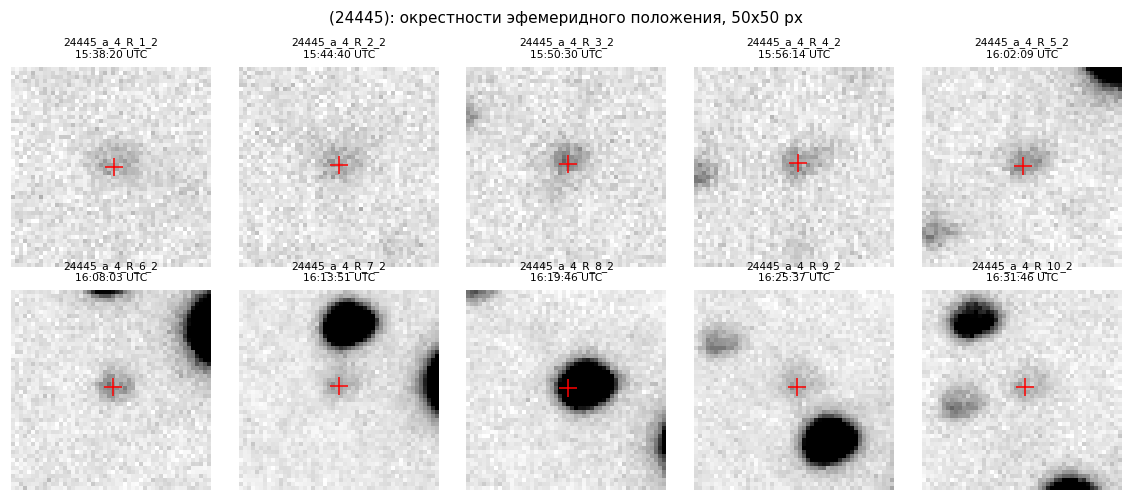

In [35]:
plot_asteroid_gallery(series)

## 8. Подробный разбор одного кадра

Кадр `vis_filename` (по умолчанию - средний кадр серии) обрабатывается с `verbose=True`:
печатается диагностика каждого шага и строятся контрольные картинки.

24445_a_4_R_6_2_stack.fits: 24445, фильтр R, 2026-09-29T16:08:03.308 UTC (JD 2461313.172261), обсерватория 217
Horizons: RA = 296.516771, DEC = 11.876796, V = 16.5, скорость 73.0"/ч, предсказанное положение x = 924.1, y = 875.2
опорных звезд Gaia в кадре: 855, ближайшая к астероиду - в 28.2 px
форма звездного профиля A,B,C = [ 0.0644 -0.0164  0.09  ] +- [0.0153 0.0117 0.0135] (FWHM ~ 6.0 px)
редукция: uwex = 0.070", uwey = 0.060", измерено звезд Ns = 787, в решении Nrs = 655, масштаб 0.0004"/px
контрольные звезды (ближайшие к астероиду):
  звезда # 333 (x=  923.1, y=  903.6): O-C ksi = +0.015", eta = +0.008"
  звезда # 336 (x=  952.1, y=  889.7): O-C ksi = +0.034", eta = +0.011"
  звезда # 337 (x=  904.1, y=  843.4): O-C ksi = +0.001", eta = -0.040"
астероид: x = 924.49, y = 875.63 (+-0.154 px), RA = 296.5167156, DEC = 11.8767819, O-C = (-0.195", -0.052"), ошибки RA*cos(DEC) = 0.058", DEC = 0.049"


,24445_a_4_R_6_2_stack.fits
FILE,24445_a_4_R_6_2_stack.fits
TARGET,24445
FILTER,R
DATE_OBS,2026-09-29T16:08:03.308
JD,2461313.172261
RA,296.516716
DEC,11.876782
ERR_RA,0.057672
ERR_DEC,0.049394
RA_EPH,296.516771


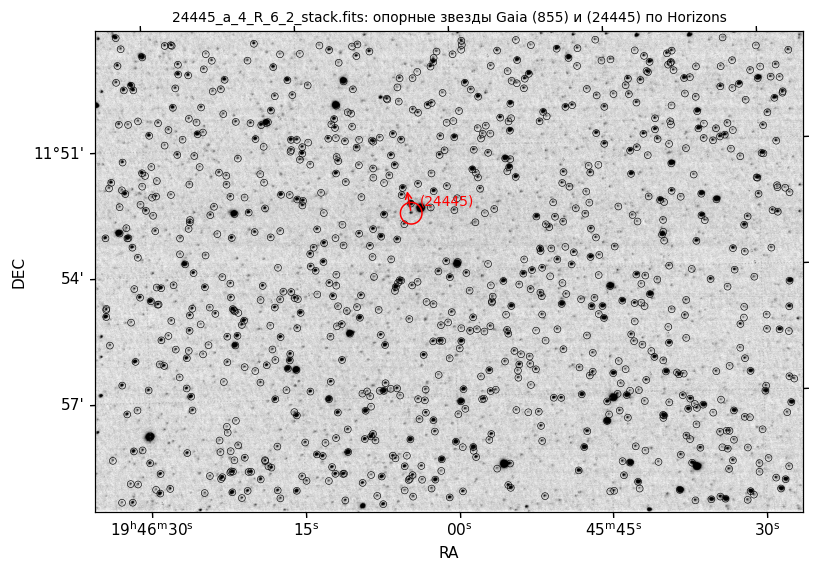

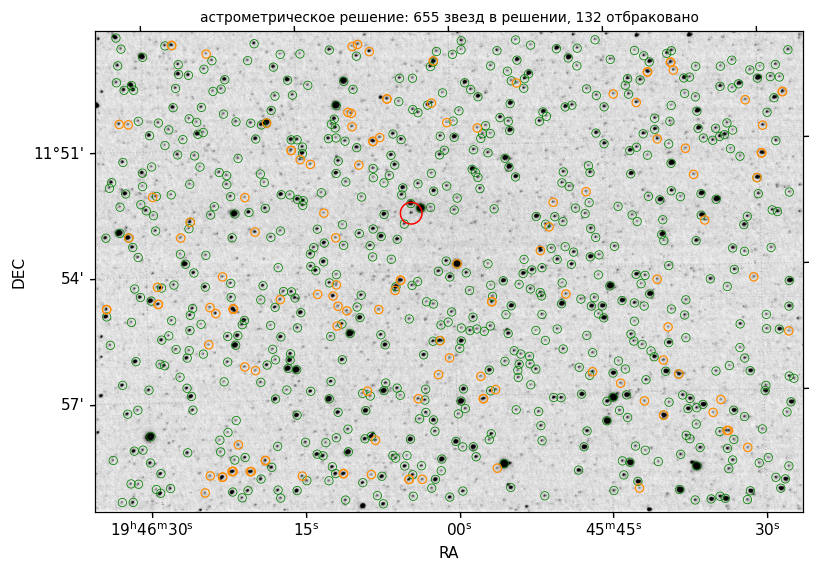

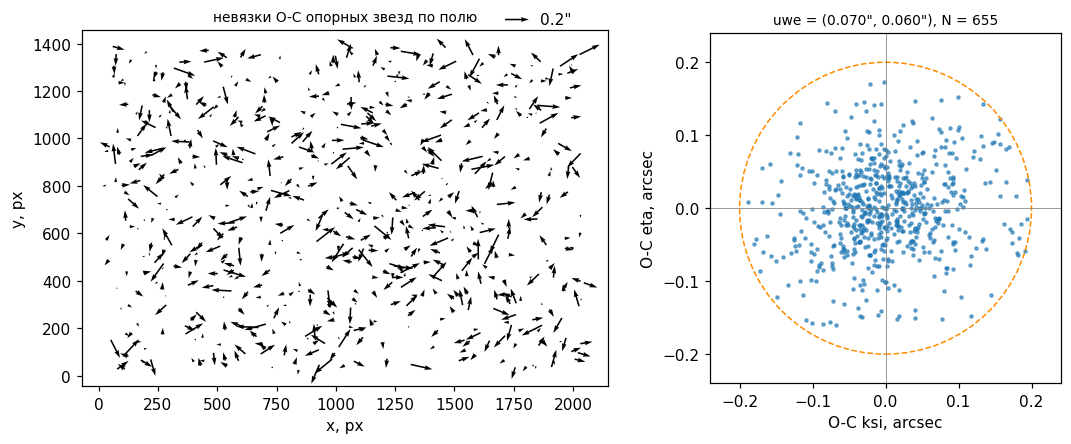

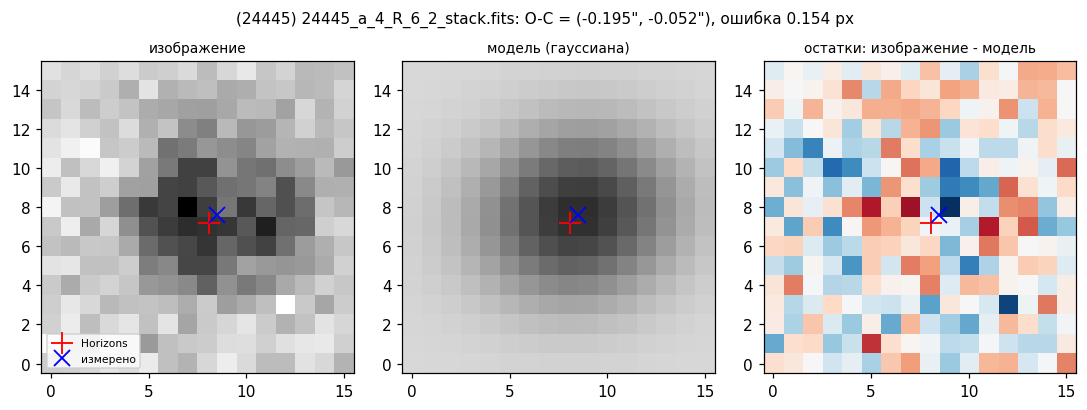

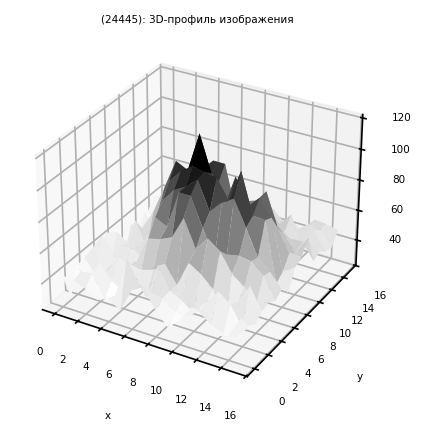

In [36]:
res_vis = process_frame(vis_filename, verbose=True)
pd.DataFrame([res_vis]).T.rename(columns={0: os.path.basename(vis_filename)})

## 9. Пакетная обработка серии

Все кадры серии обрабатываются без картинок. Кадр, на котором обработка упала, пропускается с
сообщением. Результаты сохраняются в `<TARGET>_<дата>_astrometry.csv` в текущей папке.

Колонки: `RA`, `DEC` - измеренные координаты (градусы, ICRF/Gaia DR3), `RA_EPH`, `DEC_EPH` - Horizons,
`ERR_RA` (по Δα·cosδ), `ERR_DEC` - ошибки положения в угловых секундах (ошибка центроида + ошибка
астрометрической модели в точке астероида, см. `position_errors`), `OMC_RA` (= Δα·cosδ), `OMC_DEC` - O-C
в угловых секундах, `ERR_PIX` - формальная ошибка центроида в пикселях, `UWE_X`, `UWE_Y` - ошибка единицы веса астрометрической редукции, `NS`/`NRS` - число
измеренных опорных звезд и вошедших в решение, `SHIFT_PIX` - расстояние измеренного положения от
эфемеридного, `STAR_DIST` - до ближайшей звезды Gaia, `FLAG` - флаги качества (см. раздел 5).

In [37]:
def batch_process(filelist, omc_thresh=omc_thresh):
    """Прогоняет process_frame по всем файлам серии и собирает итоговую таблицу. Кадр, упавший с
    исключением, пропускается с сообщением, а не прерывает всю обработку."""
    rows = []
    for f in filelist:
        t_start = time.time()
        try:
            r = process_frame(f, verbose=False, omc_thresh=omc_thresh)
        except Exception as e:
            print(f'{os.path.basename(f)}: пропущен из-за ошибки: {e}')
            continue
        rows.append(r)
        print(f"{r['FILE']}: O-C = ({r['OMC_RA']:+.3f}\", {r['OMC_DEC']:+.3f}\") "
              f"+-({r['ERR_RA']:.3f}\", {r['ERR_DEC']:.3f}\"), Nrs = {r['NRS']} {r['FLAG']}  [{time.time()-t_start:.1f} с]")
    return pd.DataFrame(rows)

resdf = batch_process(filelist)
if len(resdf):
    out_csv = f"{resdf['TARGET'].iloc[0]}_{resdf['DATE_OBS'].iloc[0][:10].replace('-','')}_astrometry.csv"
    resdf.to_csv(out_csv, index=False, float_format='%.8f')
    print(f'сохранено: {out_csv}')
else:
    print('ни один файл не дал измерений')
resdf.round({'RA':7,'DEC':7,'RA_EPH':7,'DEC_EPH':7,'OMC_RA':3,'OMC_DEC':3,'X':2,'Y':2,
             'ERR_RA':3,'ERR_DEC':3,'ERR_PIX':3,'SHIFT_PIX':2,'STAR_DIST':1,'UWE_X':3,'UWE_Y':3})

24445_a_4_R_1_2_stack.fits: O-C = (-0.064", -0.049") +-(0.118", 0.078"), Nrs = 352   [1.6 с]
24445_a_4_R_2_2_stack.fits: O-C = (+0.221", -0.039") +-(0.107", 0.091"), Nrs = 311   [1.7 с]
24445_a_4_R_3_2_stack.fits: O-C = (+0.224", +0.161") +-(0.066", 0.062"), Nrs = 367   [1.7 с]
24445_a_4_R_4_2_stack.fits: O-C = (-0.157", +0.199") +-(0.092", 0.069"), Nrs = 449   [1.8 с]
24445_a_4_R_5_2_stack.fits: O-C = (-0.144", -0.151") +-(0.072", 0.055"), Nrs = 418   [1.8 с]
24445_a_4_R_6_2_stack.fits: O-C = (-0.195", -0.052") +-(0.058", 0.049"), Nrs = 655   [1.7 с]
24445_a_4_R_7_2_stack.fits: O-C = (-0.140", -1.330") +-(0.087", 0.209"), Nrs = 542 bs?  [1.8 с]
24445_a_4_R_8_2_stack.fits: O-C = (-2.060", +0.269") +-(0.029", 0.023"), Nrs = 548 bs?  [1.7 с]
24445_a_4_R_9_2_stack.fits: O-C = (-2.099", +3.577") +-(1.175", 1.852"), Nrs = 431 se?  [1.8 с]
24445_a_4_R_10_2_stack.fits: O-C = (+0.012", +0.033") +-(0.091", 0.071"), Nrs = 424   [1.9 с]
сохранено: 24445_20260929_astrometry.csv


,FILE,TARGET,FILTER,DATE_OBS,JD,RA,DEC,ERR_RA,ERR_DEC,RA_EPH,...,X,Y,ERR_PIX,SHIFT_PIX,STAR_DIST,UWE_X,UWE_Y,NS,NRS,FLAG
0,24445_a_4_R_1_2_stack.fits,24445,R,2026-09-29T15:38:20.819,2.461313e+06,296.515164,11.886702,0.118,0.078,296.515182,...,937.99,803.69,0.289,1.39,52.4,0.068,0.063,459,352,
1,24445_a_4_R_2_2_stack.fits,24445,R,2026-09-29T15:44:40.683,2.461313e+06,296.515581,11.884592,0.107,0.091,296.515518,...,934.64,818.97,0.286,1.00,39.4,0.080,0.065,478,311,
2,24445_a_4_R_3_2_stack.fits,24445,R,2026-09-29T15:50:30.554,2.461313e+06,296.515893,11.882701,0.066,0.062,296.515829,...,931.79,833.17,0.183,0.92,29.8,0.086,0.063,635,367,
3,24445_a_4_R_4_2_stack.fits,24445,R,2026-09-29T15:56:14.450,2.461313e+06,296.516092,11.880797,0.092,0.069,296.516136,...,930.07,846.67,0.234,0.83,25.5,0.073,0.087,677,449,
4,24445_a_4_R_5_2_stack.fits,24445,R,2026-09-29T16:02:09.646,2.461313e+06,296.516413,11.878723,0.072,0.055,296.516454,...,927.75,861.97,0.183,1.59,28.8,0.087,0.081,686,418,
5,24445_a_4_R_6_2_stack.fits,24445,R,2026-09-29T16:08:03.308,2.461313e+06,296.516716,11.876782,0.058,0.049,296.516771,...,924.49,875.63,0.154,0.59,28.2,0.070,0.060,787,655,
6,24445_a_4_R_7_2_stack.fits,24445,R,2026-09-29T16:13:51.880,2.461313e+06,296.517045,11.874486,0.087,0.209,296.517085,...,922.05,893.11,0.462,3.72,14.0,0.077,0.065,694,542,bs?
7,24445_a_4_R_8_2_stack.fits,24445,R,2026-09-29T16:19:46.934,2.461313e+06,296.516821,11.872953,0.029,0.023,296.517406,...,923.32,904.29,0.073,4.53,4.4,0.073,0.068,691,548,bs?
8,24445_a_4_R_9_2_stack.fits,24445,R,2026-09-29T16:25:37.673,2.461313e+06,296.517128,11.871918,1.175,1.852,296.517724,...,921.39,911.95,4.480,8.19,16.4,0.080,0.064,625,431,se?
9,24445_a_4_R_10_2_stack.fits,24445,R,2026-09-29T16:31:46.350,2.461313e+06,296.518062,11.868880,0.091,0.071,296.518059,...,914.19,933.44,0.234,0.82,17.8,0.084,0.073,643,424,


## 10. Итоги по серии

Трек астероида на кадре `vis_filename` (Horizons и измеренные положения) и O-C относительно Horizons
от времени. Для нумерованного астероида с хорошей орбитой средний O-C должен быть близок к нулю
в пределах точности редукции; систематический сдвиг по RA часто указывает на ошибку в моменте
наблюдения (1 с ошибки времени = скорость(″/ч)/3600 ″ сдвига вдоль направления движения) -
`estimate_time_offset` оценивает этот сдвиг по серии.

отбракованы: 24445_a_4_R_7_2_stack.fits [be], 24445_a_4_R_8_2_stack.fits [bs?], 24445_a_4_R_10_2_stack.fits [e]
O-C по 6 из 9 измерений: RA*cos(DEC) = -0.035" +- 0.223", DEC = +0.031" +- 0.141"
вдоль трека O-C соответствует сдвигу времени dt = -1.8 +- 2.8 с (DATE_OBS_MODE = 'start'); поперек трека: +0.029" +- 0.091"


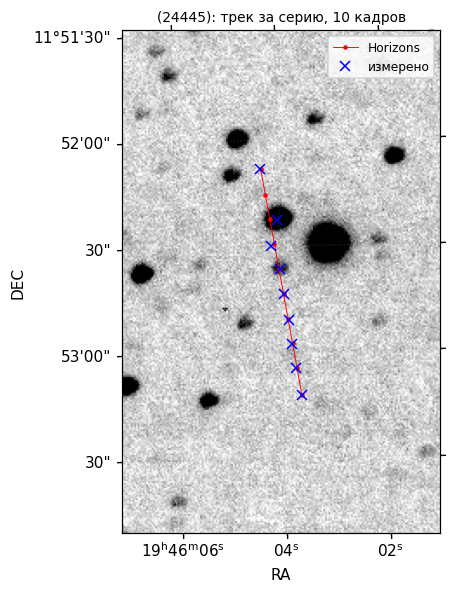

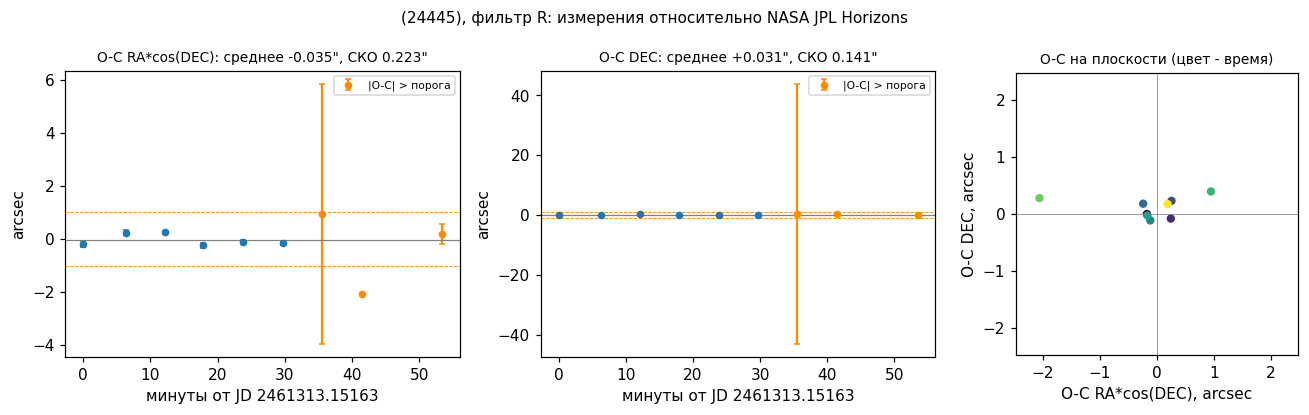

In [26]:
if len(resdf):
    plot_series_track(read_frame(vis_filename), series, resdf)
    plot_series_results(resdf)
    ok = resdf['FLAG']==''
    print('отбракованы:', ', '.join(f"{f} [{g}]" for f, g in zip(resdf['FILE'][~ok], resdf['FLAG'][~ok])) or 'нет')
    print(f"O-C по {ok.sum()} из {len(resdf)} измерений: "
          f"RA*cos(DEC) = {resdf['OMC_RA'][ok].mean():+.3f}\" +- {resdf['OMC_RA'][ok].std():.3f}\", "
          f"DEC = {resdf['OMC_DEC'][ok].mean():+.3f}\" +- {resdf['OMC_DEC'][ok].std():.3f}\"")
    to = estimate_time_offset(resdf)
    print(f"вдоль трека O-C соответствует сдвигу времени dt = {to['dt']:+.1f} +- {to['dt_err']:.1f} с "
          f"(DATE_OBS_MODE = '{DATE_OBS_MODE}'); поперек трека: {to['cross']:+.3f}\" +- {to['cross_err']:.3f}\"")
    if abs(to['dt']) > 3*to['dt_err'] and abs(to['dt']) > 5:
        print('  -> значимая ошибка момента наблюдения: проверьте DATE_OBS_MODE и часы регистрации времени')

## 11. Итог: координаты астероида по серии

Итоговая таблица `result` (только кадры без флагов качества): момент наблюдения `JD` (UTC, середина экспозиции), измеренные `RA`, `DEC`
(градусы, ICRF, система Gaia DR3) и их ошибки `ERR_RA` (по Δα·cosδ), `ERR_DEC` в угловых секундах.
Сохраняется в `<TARGET>_<дата>_radec.csv`.

In [27]:
result = resdf.loc[resdf['FLAG']=='', ['JD','RA','DEC','ERR_RA','ERR_DEC']].reset_index(drop=True)
if len(result):
    out_csv = f"{resdf['TARGET'].iloc[0]}_{resdf['DATE_OBS'].iloc[0][:10].replace('-','')}_radec.csv"
    result.to_csv(out_csv, index=False, float_format='%.9f')
    print(f'сохранено: {out_csv}')
result.style.format({'JD':'{:.6f}','RA':'{:.7f}','DEC':'{:.7f}','ERR_RA':'{:.3f}','ERR_DEC':'{:.3f}'})

сохранено: 24445_20260929_radec.csv


,JD,RA,DEC,ERR_RA,ERR_DEC
0,2461313.151630,296.5151319,11.8867157,0.113,0.082
1,2461313.156026,296.5155871,11.8845802,0.105,0.090
2,2461313.160076,296.5159017,11.8827194,0.062,0.062
3,2461313.164056,296.5160674,11.8807919,0.089,0.062
4,2461313.168167,296.5164203,11.8787336,0.067,0.052
5,2461313.172261,296.5167234,11.8767882,0.058,0.049
